# Deep neural networks for modal decomposition of flow-field data
## Contents
### 1.   Autoencoders

*   Non-linear dimension reduction
*   Approximation of the Koopman operator

### 2.   Convolutional neural network (CNN) based autoencoders


*   Convolution operation, down-sampling, and up-sampling
*   CNNs for modal decomposition




*Based on the material developed by Hamidreza Eivazi and Ricardo Vinuesa (KTH), adapted by Artem Kulachenko and Marta Alloisio. Extended for the TekMek AI retreat 2026 with labelled convolution kernels and a look at the kernels the network learns.*

# Tasks

1.   Implement an AE-based model to approximate the Koopman operator.
2.   Implement a CNN-based autoencoder.


## Dataset

The dataset is obtained from a DNS simulation of 2D viscous flow past two colinear  plates, aligned perpendicular to the freestream velocity. The plates each have unit length, and the gap between them is also unity. The Reynolds number (based on freestream velocity and the length of one plate) is 100.

The data is stored in a 4D NumPy array with the shape of $(n_t, n_x, n_y, n_v)$ where $n_t$ indicates the number of time snapshots. $n_x$ and $n_y$ are the number of grid points in $x$ and $y$ directions, respectively, and $n_v$ represents the number of variables, which are velocity components $u$ and $v$.

### Flow configuration

Two plates of length $L = 1$, separated by a gap of $L = 1$, stand perpendicular to a uniform free stream $U_\infty$ at $Re = U_\infty L/\nu = 100$. The wake behind the plates is unsteady, and this velocity field is the data we compress below.

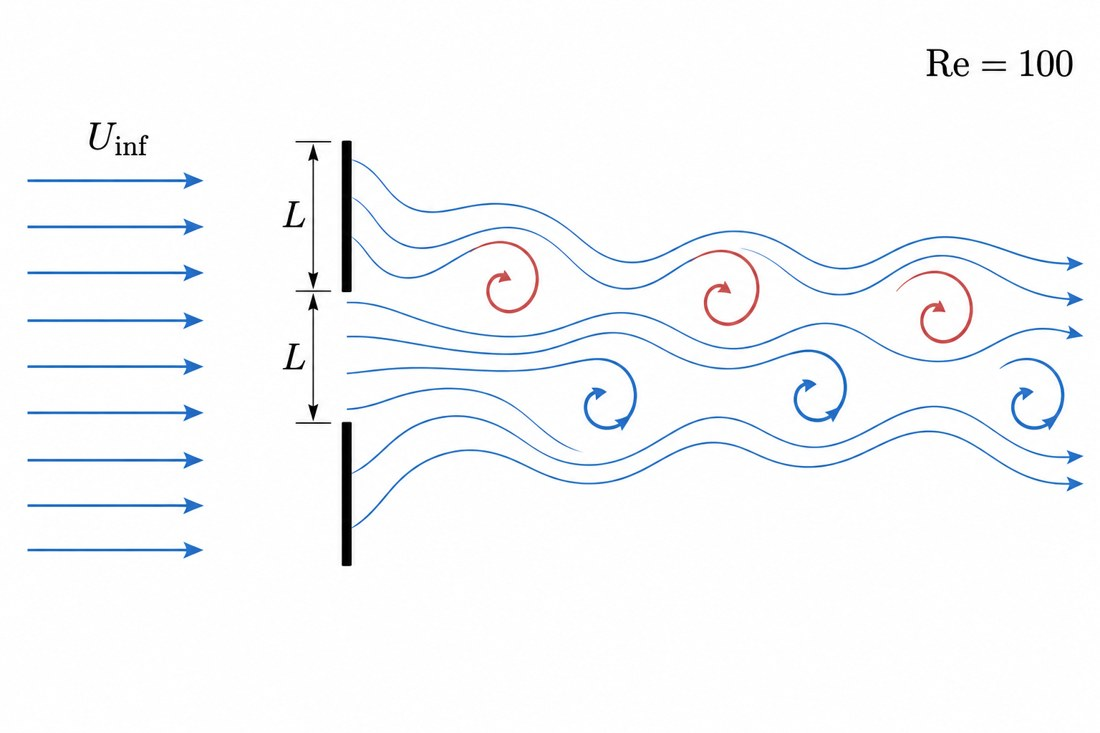

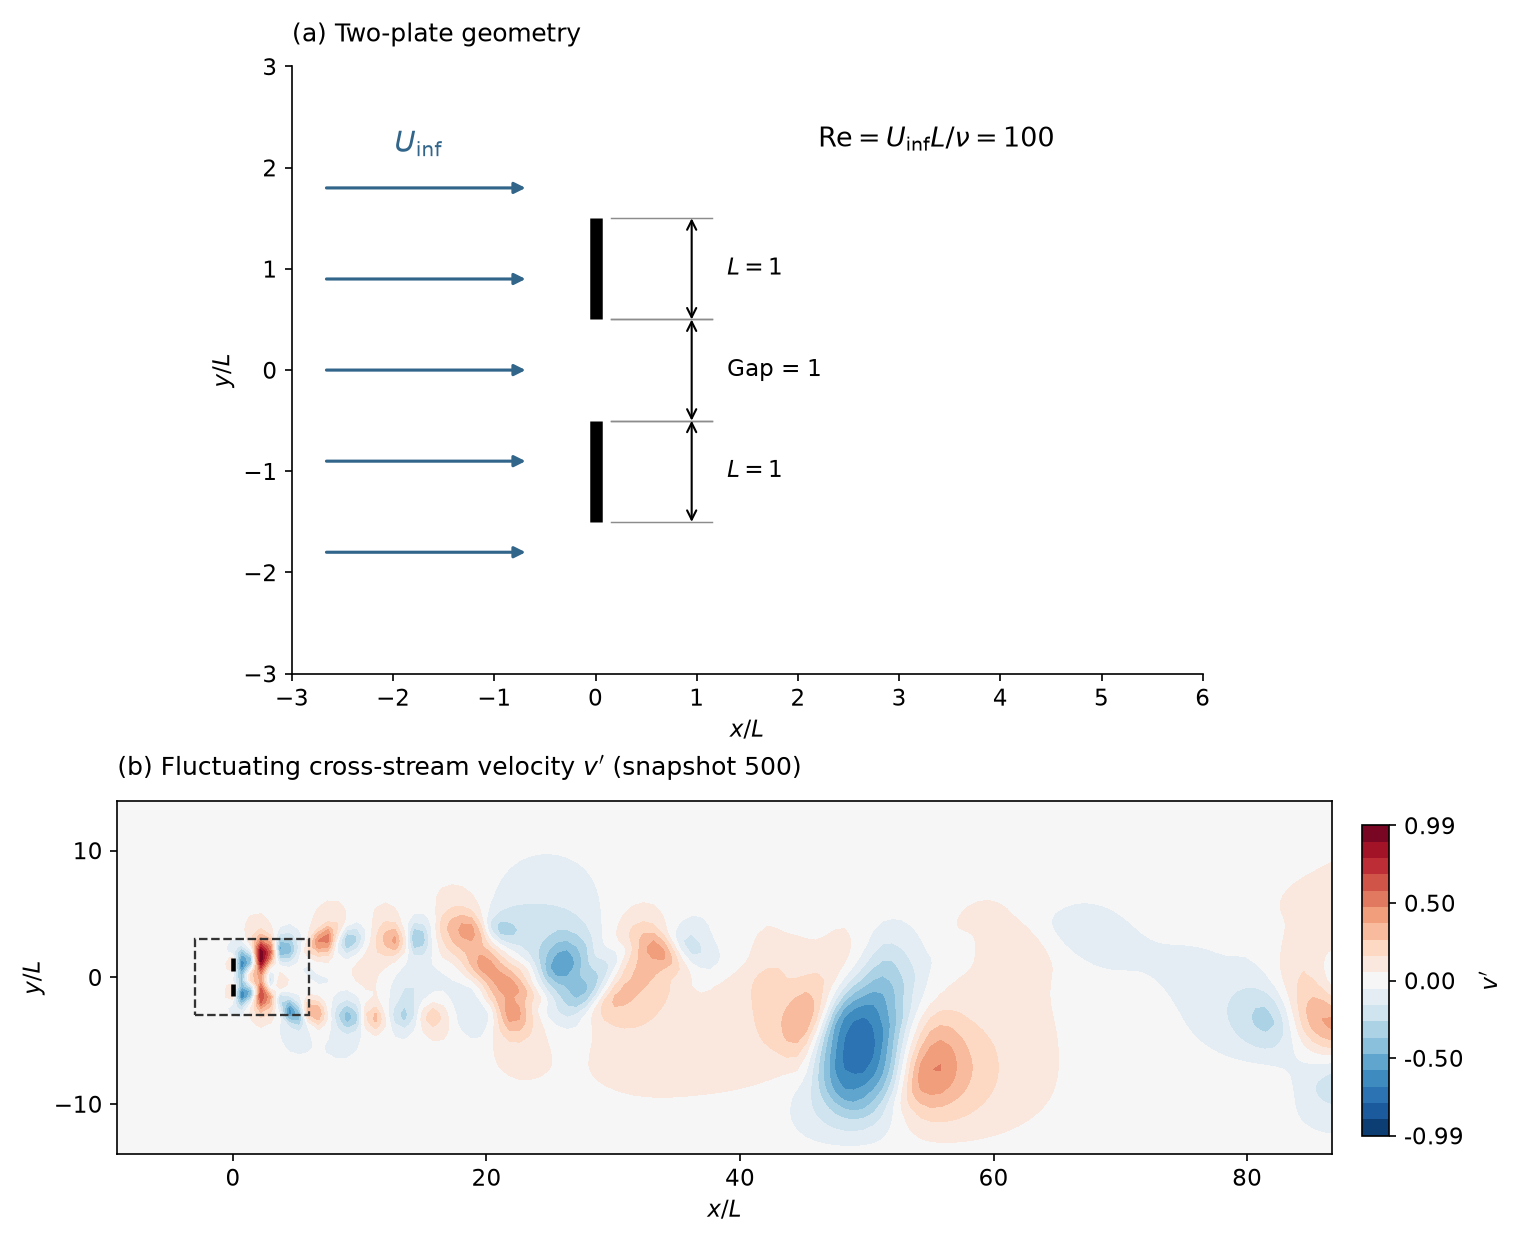

*Top: illustration of the configuration. Bottom: (a) geometry near the plates; (b) fluctuating cross-stream velocity $v'$ from the dataset, with the dashed box marking the region in (a).*


## Import required packages and load the data

In [ ]:
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras import layers, models, activations, optimizers, callbacks
import gdown

url = 'https://drive.google.com/uc?id=1b_pJl1XBfzlb93IcB4USht1voHBW6-IE'
output = 'data.npz'

gdown.download(url, output, quiet=False)

# download the data (a DNS of the flow past two plates) from Google Drive
import gdown
gdown.download('https://drive.google.com/uc?id=1b_pJl1XBfzlb93IcB4USht1voHBW6-IE', 'data.npz', quiet=False)


We load the data into NumPy arrays. The data is stored on a uniformly-spaced 2D grid (the original simulation has higher resolution).

In [ ]:
data = np.load('data.npz')
v = data['UV']
xx = data['x']
yy = data['y']

We can remove the mean flow from the data.



In [ ]:
v_mean = v.mean(axis = 0)
v -= v_mean

print(v.shape)

Now, let's plot the data.

In [ ]:
fig, ax = plt.subplots(1, 2, sharex = True, sharey = True, figsize = (16, 4))
plt.set_cmap('RdBu_r')

ax[0].contourf(xx, yy, v[0, :, :, 0], levels = 20)
ax[1].contourf(xx, yy, v[0, :, :, 1], levels = 20)

ax[0].set_xlabel('x')
ax[1].set_xlabel('x')

ax[0].set_ylabel('y')

ax[0].set_title('u')
ax[1].set_title('v')

ax[0].set_aspect('equal')
ax[1].set_aspect('equal')

# Autoencoders

An autoencoder is a deep neural network (DNN) with an architecture suitable for unsupervised feature extraction. The network comprises of two parts: an encoder that maps the input data to a low-dimensional latent space $\boldsymbol{x} \mapsto \boldsymbol{z}$, and a decoder that projects the latent vector $\boldsymbol{z}$ back to the reference space $\boldsymbol{z} \mapsto \boldsymbol{\tilde{x}}$. We refer to the encoder and decoder parts as $\phi$ and $\psi$, respectively. Through the model training, the autoencoder learns to extract the most important features in the data that are required for reconstruction by optimizing the model parameters $\boldsymbol{w}$ to minimize the reconstruction loss $\mathcal{L}_\mathrm{rec}$:

$$\mathcal{F} = \phi \circ \psi,$$

$$\boldsymbol{\tilde{x}} = \mathcal{F}(\boldsymbol{x}; \boldsymbol{w}),$$

$$\mathcal{L}_\mathrm{rec} = \epsilon(\boldsymbol{x}, \boldsymbol{\tilde{x}}),$$ 

where $\boldsymbol{x}$ denotes the input data; $\boldsymbol{\tilde{x}}$ is the reconstruction of the input data and $\epsilon$ represents the loss function. The autoencoder architecture is attractive for modal decomposition as it provides a framework that can incorporate non-linearity in the mappings through the use of non-linear activation functions. 

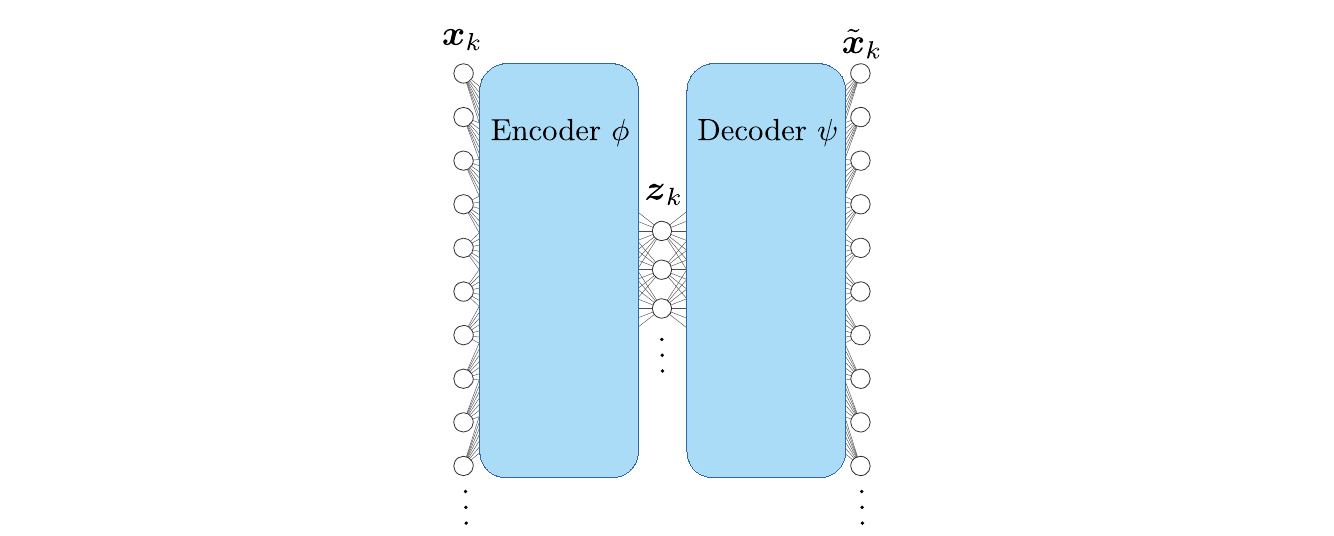

### Non-linear dimension reduction

In the following, we implement a simple autoencoder and use it for non-linear dimension reduction. Let's consider $80\%$ of the data for training and $20\%$ for validation. 

In [ ]:
nt, nx, ny, nv = v.shape
v_trn, v_val = train_test_split(v, test_size = 0.2, random_state = 24, shuffle = True)

In [ ]:
d = 10
act = activations.relu

n_state_variables = nx * ny * nv
n_hl_1 = 512

### Encoder

In [ ]:
inp = layers.Input(shape = (nx, ny, nv))
x = layers.Flatten()(inp)
x = layers.Dense(n_hl_1, activation=act)(x)
code = layers.Dense(d)(x)

encoder = models.Model(inp, code)
print(encoder.summary())

### Decoder

In [ ]:
code_d = layers.Input(shape = (d,))
x = layers.Dense(n_hl_1, activation=act)(code_d)
x = layers.Dense(n_state_variables)(x)
out = layers.Reshape((nx, ny, nv))(x)


decoder = models.Model(code_d, out)
print(decoder.summary())

### Autoencoder

In [ ]:
out_d = decoder(encoder(inp))

model = models.Model(inp, out_d)
print(model.summary())

## Model training

### Callbacks
We use early stopping and save the best model based on the validation loss to avoid overfitting. 

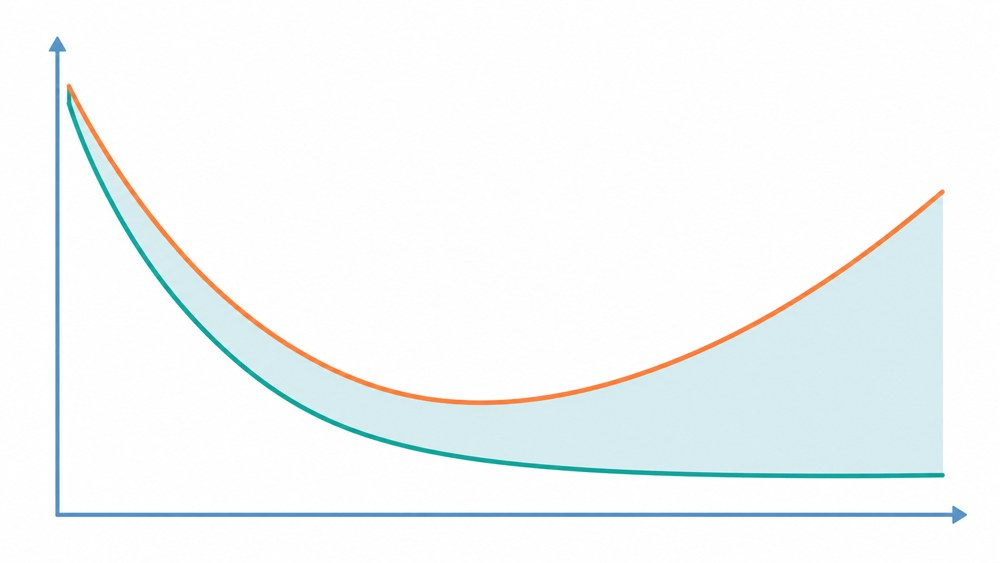

*Training error keeps falling while the validation error turns up: the network starts to memorise. Early stopping keeps the model at the minimum of the validation error.*

In [ ]:
Es = callbacks.EarlyStopping(monitor='val_loss', patience = 20)

checkpoint_filepath = 'checkpoint_NN.weights.h5'
checkpoint = callbacks.ModelCheckpoint(
    filepath=checkpoint_filepath,
    save_weights_only=True,
    monitor='val_loss',
    mode='min',
    save_best_only=True)

callbacks_list = [Es, checkpoint]

### Optimizer, loss function, and model training

We employ Adam with a piecewise constant decay of the learning rate as the optimizer and the mean-squared error as the loss function.

In [ ]:
step = tf.Variable(0, trainable=False)
boundaries = [100, 100]
values = [1e-3, 1e-4, 1e-5]
lr = optimizers.schedules.PiecewiseConstantDecay(boundaries, values)

opt = optimizers.Adam(learning_rate = lr)
model.compile(optimizer = opt, loss = 'mse')


hist = model.fit(v_trn, v_trn, epochs = 200, callbacks = callbacks_list, validation_data = (v_val, v_val), verbose = 2)

### Saving the best model based on the validation loss

In [ ]:
model.load_weights(checkpoint_filepath)
model_name = f'NN_AE_{d}'

encoder.save(model_name + '_encoder.keras')
decoder.save(model_name + '_decoder.keras')

### Flow field reconstruction

Now, we can compare the reconstruction of the flow field for a snapshot from the validation data with the reference data.

In [ ]:
v_val_rec = model.predict(v_val)

fig, ax = plt.subplots(2, 2, sharex = True, sharey = True, figsize = (10, 4))

plt.set_cmap('RdBu_r')

vmin0 = v_val[-1, :, :, 0].min()
vmax0 = v_val[-1, :, :, 0].max()

vmin1 = v_val[-1, :, :, 1].min()
vmax1 = v_val[-1, :, :, 1].max()

ax[0, 0].contourf(xx, yy, v_val[-1, :, :, 0], vmin = vmin0, vmax = vmax0, levels = 20)
ax[1, 0].contourf(xx, yy, v_val[-1, :, :, 1], vmin = vmin1, vmax = vmax1, levels = 20)

ax[0, 1].contourf(xx, yy, v_val_rec[-1, :, :, 0], vmin = vmin0, vmax = vmax0, levels = 20)
ax[1, 1].contourf(xx, yy, v_val_rec[-1, :, :, 1], vmin = vmin1, vmax = vmax1, levels = 20)


ax[0, 0].set_ylabel('y')
ax[1, 0].set_ylabel('y')
ax[1, 0].set_xlabel('x')
ax[1, 1].set_xlabel('x')

ax[0, 0].set_title('$u$ reference')
ax[1, 0].set_title('$v$ reference')
ax[0, 1].set_title('$u$ reconstruction')
ax[1, 1].set_title('$v$ reconstruction')

for axx in ax.flatten():
  axx.set_aspect('equal')

fig.tight_layout()

Moreover, we can define the error in the reconstructions as the average relative $\ell_2$-norm of errors for all the snapshots as:

\begin{equation}
\boldsymbol{\epsilon} = \dfrac{1}{n_t}\sum_{i = 1}^{i = n_t}\dfrac{||\boldsymbol{v} - \boldsymbol{\tilde{v}}||}{||\boldsymbol{v}||},
\end{equation}
where $||\cdot||$ indicates $\ell_2$-norm. 

In [ ]:
def error_rec(v, v_p):
  err = np.linalg.norm(v - v_p, axis = (1, 2))/ np.linalg.norm(v, axis = (1, 2))
  err = np.mean(err, axis = 0)
  return err

v_rec = model.predict(v)
error = error_rec(v, v_rec)
print(error)

## Background: Proper Orthogonal Decomposition (POD)

POD is the linear baseline that the autoencoder will be compared with. It splits the flow into a few fixed spatial patterns (modes) and a time signal for each.

**Snapshots.** Each of the $n_t$ velocity fields $v(x, t_k)$ is flattened into a column. The columns form the snapshot matrix $X$ of size $(n_x n_y \cdot 2) \times n_t$.

**SVD.** $X = U \Sigma V^T$.
- The columns of $U$ are the spatial modes $\phi_i(x)$, orthonormal.
- The singular values $\sigma_1 \ge \sigma_2 \ge \dots$ rank the modes by energy: $\sigma_i^2$ is proportional to the kinetic energy that mode $i$ carries. Here the mean is not subtracted, so mode 1 is close to the mean flow.
- Row $i$ of $\Sigma V^T$ is the time coefficient $a_i(t)$ of mode $i$.

**Truncation.** Keeping the first $d$ modes gives

$$v(x, t) \approx \sum_{i=1}^{d} a_i(t)\, \phi_i(x).$$

For a given $d$, no other linear basis reconstructs the snapshots with a smaller squared error.

**The parallel with structural dynamics.**

| Structural dynamics | POD of a flow |
|---|---|
| Eigenmodes $\phi_i$ from $(K - \omega_i^2 M)\phi_i = 0$ | POD modes $\phi_i$ from the SVD of the snapshots |
| Modal superposition $u(x,t) = \sum q_i(t)\, \phi_i(x)$ | $v(x,t) = \sum a_i(t)\, \phi_i(x)$ |
| Keep the lowest few modes (modal truncation) | Keep the most energetic few modes |
| Modes come from the model ($K$, $M$) | Modes come from data (measured or simulated fields) |

POD modes are the eigenvectors of the spatial correlation matrix $X X^T$, so the idea is the same: an eigenvalue problem gives a basis, and a few basis vectors describe the motion. The difference is the ranking: eigenmodes are ranked by frequency, POD modes by energy.

**Why the autoencoder.** POD is linear: the field is a weighted sum of fixed modes. The vortices in the wake travel downstream, and a travelling pattern needs many fixed modes. The CNN autoencoder below also compresses each field to $d$ numbers, but its decoder is nonlinear. With the same $d$ it can reconstruct the field better than POD.

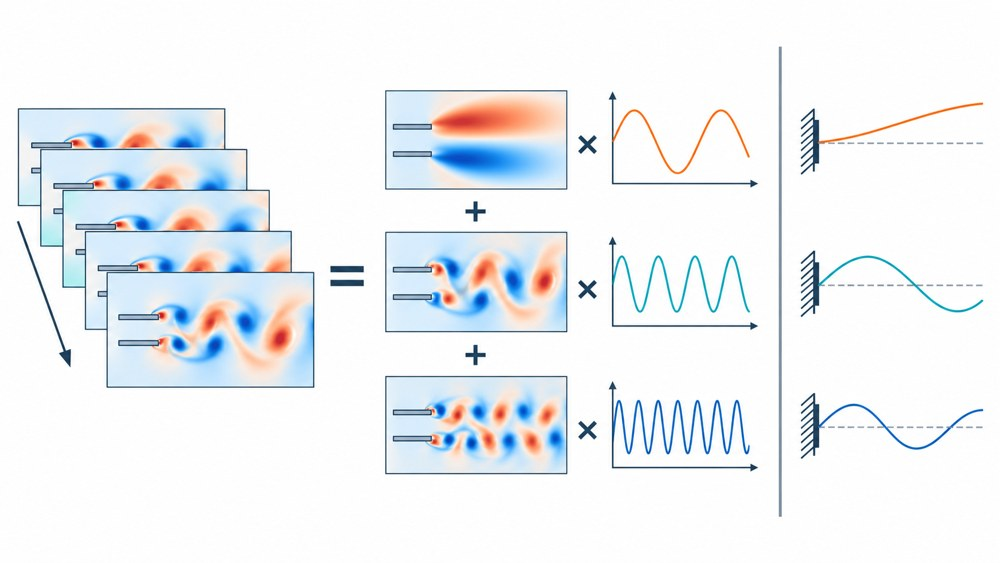

*Left: snapshots of the wake. Middle: POD writes them as a sum of spatial modes, each multiplied by its own time coefficient. Right: the same idea in structural dynamics, the first bending modes of a cantilever.*

###Flow field reconstruction using POD

In [ ]:
U, s, vh = np.linalg.svd(v.reshape((nt, -1)).T, full_matrices=False)
v_pod = U[:, :d] @ np.diag(s[:d]) @ vh[:d]

v_pod = v_pod.T.reshape((-1, nx, ny, 2))
pod_err = error_rec(v, v_pod)
print(pod_err)

U = U.T.reshape((-1, nx, ny, 2))

# Approximation of the Koopman operator

Here, we provide a brief overview of the mathematical aspects. Let's focus on an autonomous discrete-time dynamical system:
\begin{equation}
    \boldsymbol{x}_{t+1} = \mathbf{F}(\boldsymbol{x}_{t}),
\end{equation}
where $\mathbf{F}$ is the evolution operator. The Koopman operator $\boldsymbol{K}$ is defined as an infinite-dimensional linear operator that acts on functions of state space $g$. The action of the Koopman operator is:

$$\boldsymbol{K} g = g \circ\mathbf{F},$$

where $\circ$ indicates the composition of $g$ with $\mathbf{F}$. 
In fact, the Koopman operator defines a new infinite-dimensional linear dynamical system that governs the evolution of the observables $g_{t} = g(\mathbf{x}_t)$ in discrete time.
The Koopman operator can be approximated through the DMD algorithm.

$$\boldsymbol{x}_{k+1} = \boldsymbol{A} \boldsymbol{x}_{k}.$$


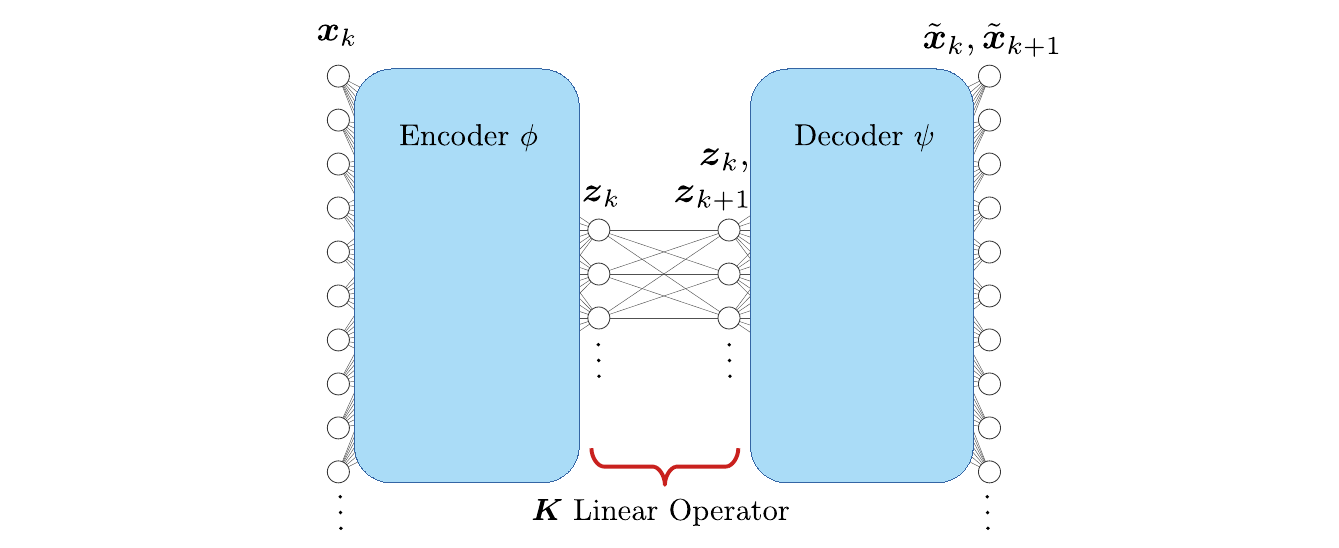

Let's prepare training and validation datasets.

In [ ]:
X_trn, X_val, y_trn, y_val = train_test_split(v[:-1], v[1:], test_size = 0.2, random_state = 24, shuffle = True)

# Task 1: Implement an AE-based model to approximate the Koopman operator. 

You need to:

1.   Build an encoder
2.   Build a model with one linear layer as the Koopman operator.
3.   Build a decoder
4.   Build a multi-output NN using the encoder, linear model, and decoder.





In [ ]:
# .
# .
# .


# model = models.Model(inp_en, [out, out_next])

# model.compile(optimizer = opt, loss = 'mse')
# hist = model.fit(X_trn, [X_trn, y_trn], epochs = 200, callbacks = callbacks_list, validation_data = (X_val, [X_val, y_val]), verbose = 2)

$~~$

# Convolutional neural network (CNN) based autoencoders

Through a two-dimensional convolution layer and using a so-called filter with size $H\times H \times K$, the data is processed as:

\begin{equation}
    \boldsymbol{x}^{(l)}_{ijm} = \varphi \left ( \sum_{k = 1}^{K} \sum_{p = 1}^{H} \sum_{q = 1}^{H} \boldsymbol{x}^{(l-1)}_{i+p, j+q, k}\boldsymbol{w}^{(l)}_{pqkm} + \boldsymbol{b}^{(l)}_{ijm} \right ),
\end{equation}

where $\boldsymbol{x}^{(l-1)}$ and $\boldsymbol{x}^{(l)}$ represent the input and output variables, respectively. Note that $\boldsymbol{w}^{(l)}$ and $\boldsymbol{b}^{(l)}$ denote the weights and the biases of layer $l$, and $\varphi$ denotes the activation function. Furthrmotr, $K$ is the number of the so-called kernels, which are the two-dimensional slices of the filter. 

It is common to use convolution layers together with the pooling and upsampling layers. Through a pooling operation, the data are compressed by a factor of $(1/P)^2$ so that a region with size of $P \times P$ is represented by e.g. its maximum value; this is the so-called max-pooling operation. 

The upsampling operation is used to expand the data dimension by e.g. nearest-neighbor or bilinear interpolation. 

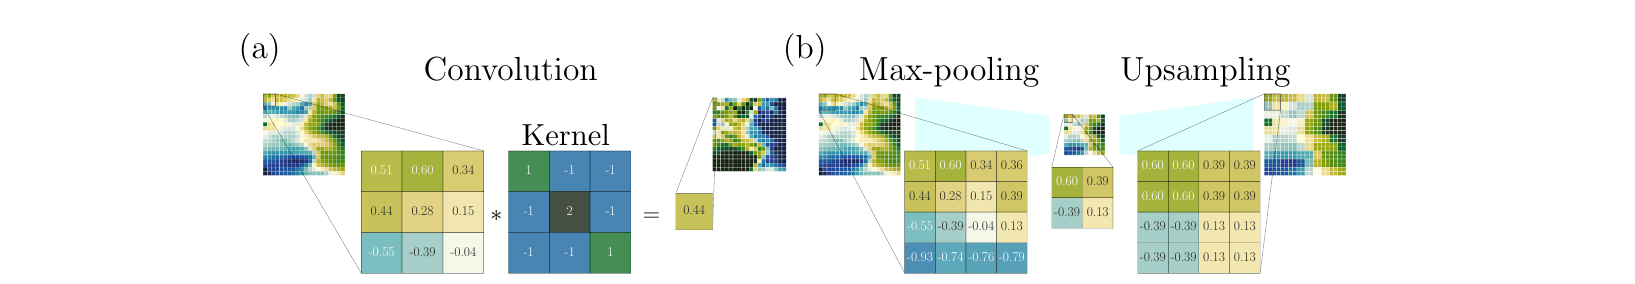

## Convolution: what a kernel does

A convolution slides a small kernel over the field and replaces every point by a weighted sum of its neighbours. We first apply kernels whose weights we choose ourselves, so that we know what to expect. Then we look at a kernel with random weights, which is how every kernel in a CNN starts before training. At the end of the notebook we look at the kernels the trained network has learned.

The kernels are printed in the corner of each plot as they lie on the plot: $x$ to the right and $y$ upwards.

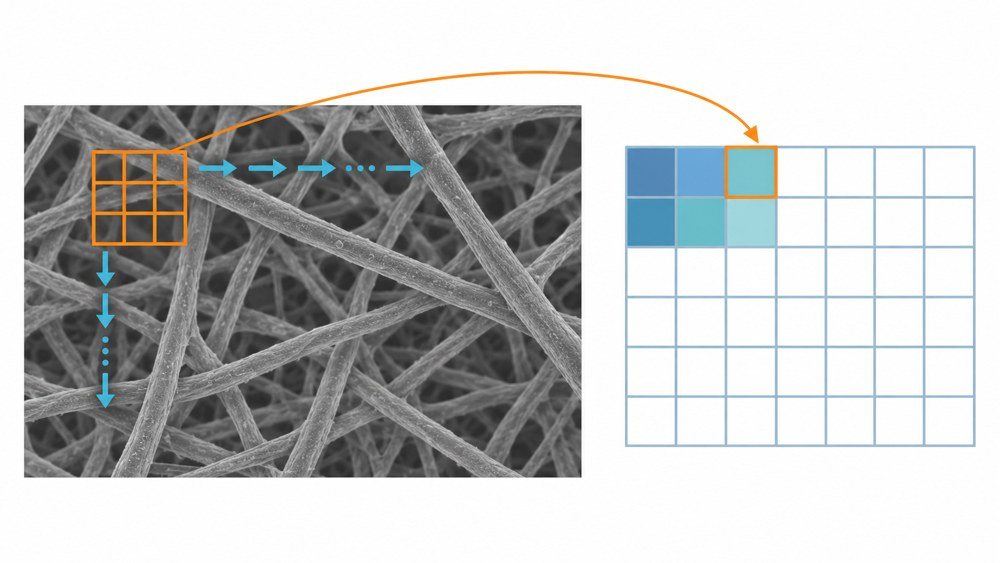

*A 3 x 3 kernel slides over the image; each position gives one value of the output feature map.*

In [ ]:
# last snapshot, u component, shape (1, nx, ny, 1): one sample, one channel
xin = v[-1:, :, :, 0:1].astype(np.float32)
print(xin.shape)


def convolve(field, kernel):
    """Apply one 2D kernel to a field of shape (1, nx, ny, 1), zero padding at the edges."""
    k = np.asarray(kernel, dtype=np.float32)[:, :, None, None]
    return tf.nn.conv2d(field, k, strides=1, padding='SAME').numpy()


def kernel_text(kernel):
    """Kernel as text, oriented as on the plot (x to the right, y upwards)."""
    k = np.flipud(np.asarray(kernel, dtype=float).T)
    return '\n'.join(' '.join(f'{w:5.2f}' for w in row) for row in k)


def show(fields, titles, kernels=None, cmap='RdBu_r'):
    """One field per row on the physical grid, the kernel printed to the right.
    Colours are capped at the 99.5th percentile so that the peaks at the plates do not hide the wake."""
    n = len(fields)
    fig, ax = plt.subplots(n, 1, figsize=(12, 2.6 * n), squeeze=False)
    ax = ax[:, 0]
    for i, (f, t) in enumerate(zip(fields, titles)):
        f = np.squeeze(f)
        step = xx.shape[0] // f.shape[0]
        lim = np.percentile(np.abs(f), 99.5)
        lo = 0 if f.min() >= 0 else -lim
        c = ax[i].contourf(xx[::step, ::step], yy[::step, ::step], np.clip(f, lo, lim),
                           levels=np.linspace(lo, lim, 21), cmap=cmap)
        fig.colorbar(c, ax=ax[i], fraction=0.02, pad=0.01, format='%.2f', ticks=np.linspace(lo, lim, 5))
        ax[i].set_title(t, loc='left')
        ax[i].set_aspect('equal')
        ax[i].set_ylabel('y')
        if kernels is not None and kernels[i] is not None:
            ax[i].text(1.13, 0.5, kernel_text(kernels[i]), transform=ax[i].transAxes, va='center',
                       family='monospace', fontsize=10, bbox=dict(facecolor='white', edgecolor='grey'))
    ax[-1].set_xlabel('x')
    fig.tight_layout()
    plt.show()

### Kernels we design ourselves

The first array index of the field runs along $x$ and the second along $y$, so a kernel that differences along the first index is a derivative in $x$. The Sobel kernel combines a central difference in one direction with a light smoothing in the other.

In [ ]:
known = {
    'identity':          np.array([[0, 0, 0], [0, 1, 0], [0, 0, 0]]),
    'box blur (average)': np.ones((3, 3)) / 9,
    'Sobel, d/dx':        np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]),
    'Sobel, d/dy':        np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]),
}
outputs = {name: convolve(xin, k) for name, k in known.items()}

show([xin] + list(outputs.values()),
     ['input $u$'] + list(outputs.keys()),
     [None] + list(known.values()))

Check that the labels are right: the Sobel outputs should match the finite-difference derivatives of $u$ (up to a constant factor, since the kernel sums 8 neighbour differences and does not divide by the grid spacing).

In [ ]:
u = xin[0, :, :, 0]
dudx, dudy = np.gradient(u)            # derivatives along the first (x) and second (y) index
inner = (slice(2, -2), slice(2, -2))   # skip the padded edges
for name, ref in [('Sobel, d/dx', dudx), ('Sobel, d/dy', dudy)]:
    out = outputs[name][0, :, :, 0]
    r = np.corrcoef(out[inner].ravel(), ref[inner].ravel())[0, 1]
    print(f'{name}: correlation with np.gradient = {r:.3f}')

The magnitude of the gradient, $\sqrt{(\partial u/\partial x)^2 + (\partial u/\partial y)^2}$, is largest in the shear layers behind the plates and at the edges of the vortices. This is edge detection, the classical use of the Sobel kernel in image processing.

In [ ]:
grad_mag = np.sqrt(outputs['Sobel, d/dx']**2 + outputs['Sobel, d/dy']**2)
show([xin, grad_mag], ['input $u$', 'gradient magnitude (Sobel)'], cmap='magma')

### A kernel with random weights

In a CNN nobody chooses the kernels. Each `Conv2D` layer starts with random weights (Glorot uniform by default) and training adjusts them to reduce the loss. Here is one such kernel before any training. Its output is a mix of smoothing and differencing with no particular purpose. Change the seed and the result changes.

In [ ]:
tf.keras.utils.set_random_seed(0)      # change the seed to get another random kernel
conv_random = layers.Conv2D(1, (3, 3), padding='same', use_bias=False)
y_random = conv_random(xin).numpy()
w_random = conv_random.get_weights()[0][:, :, 0, 0]

show([xin, y_random], ['input $u$', 'random kernel, untrained'], [None, w_random])

## Max-pooling

Max-pooling keeps the largest value in each $2 \times 2$ block, so the field becomes half as large in each direction.

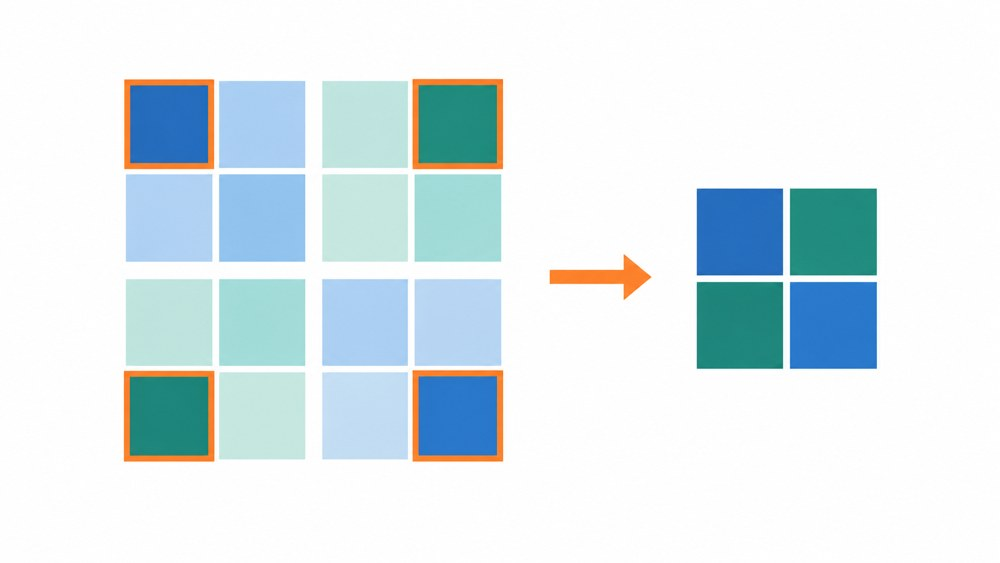

*Max-pooling keeps the strongest value of each 2 x 2 block.*

In [ ]:
max_pool_2d = layers.MaxPooling2D(pool_size=2, padding='same')
ymp = max_pool_2d(xin).numpy()
print(xin.shape, '->', ymp.shape)

show([xin, ymp], [f'input $u$ {xin.shape[1]}x{xin.shape[2]}', f'max-pooled {ymp.shape[1]}x{ymp.shape[2]}'])

## Up-sampling

Up-sampling repeats each value in a $2 \times 2$ block. It restores the size, not the detail that pooling removed.

In [ ]:
upsample_2d = layers.UpSampling2D(size=2)
yup = upsample_2d(ymp).numpy()
print(ymp.shape, '->', yup.shape)

show([xin, ymp, yup], ['input $u$', 'max-pooled', 'pooled, then up-sampled'])

# Task 2: Implement a CNN-based autoencoder.
You need to:


1.   Use Conv2D, MaxPooling2D, and UpSampling2D
2.   Find the best architecture and hyperparameters



### Encoder

In [ ]:
# d = 10
# act = activations.relu
# fs = (3, 3)
# ffs = (2, 2)
# st = (1, 1)

# inp = layers.Input(shape = (nx, ny, nv))
# x = layers.Conv2D(32, fs, activation = act, strides = st, padding='same')(inp)
# x = layers.MaxPooling2D(ffs, padding = 'same')(x)
# .
# .
# .
# code = ...

# encoder = models.Model(inp, code)
# print(encoder.summary())


### Decoder

In [ ]:
# code_d = layers.Input(shape = (d,))
# .
# .
# .
# out = ...

# decoder = models.Model(code_d, out)
# print(decoder.summary())

### Autoencoder

In [ ]:
# out_d = decoder(encoder(inp))

# model = models.Model(inp, out_d)
# print(model.summary())

## What did the network learn?

We now open the first convolution layer of the trained encoder. Each of its kernels has two slices, one for $u$ and one for $v$. Below are the $u$ slices of the eight kernels with the largest weights, and under each one its feature map: the actual output of that kernel (after bias and ReLU) for the snapshot we used above. The title says which designed kernel it resembles most, measured by the cosine similarity of the weights, when that similarity is at least 0.5.

Run this section after Task 2, once your CNN autoencoder is trained.

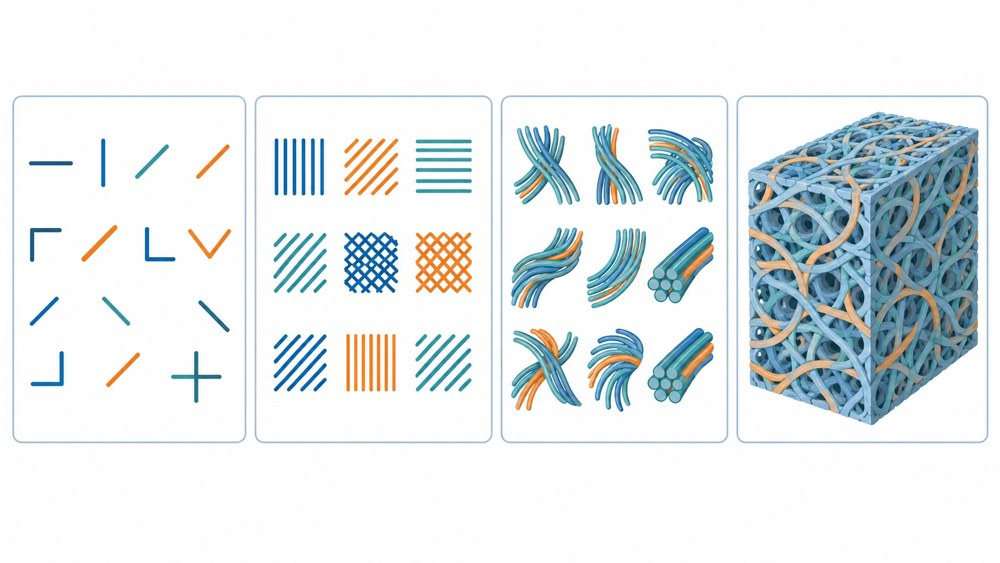

*Deeper layers respond to larger patterns: edges, textures, fibre-like structures, a whole material structure.*

In [ ]:
convs = [l for l in encoder.layers if isinstance(l, layers.Conv2D)]
if not convs:
    raise RuntimeError('The encoder has no convolution layer: build and train the CNN autoencoder (Task 2) first.')
first_conv = convs[0]
W = first_conv.get_weights()[0]                      # shape (3, 3, input channels, number of kernels)
feature_model = models.Model(encoder.inputs, first_conv.output)
fmaps = feature_model.predict(v[-1:], verbose=0)[0]  # shape (nx, ny, number of kernels)

reference = {name: k / np.linalg.norm(k) for name, k in known.items()}
order = np.argsort(-np.linalg.norm(W[:, :, 0, :], axis=(0, 1)))[:8]

fig = plt.figure(figsize=(18, 10))
gs = fig.add_gridspec(4, 4, width_ratios=[1, 5, 1, 5])
for j, m in enumerate(order):
    row, col = j % 4, 2 * (j // 4)
    k = W[:, :, 0, m]
    sims = {name: float(np.sum(k * r) / np.linalg.norm(k)) for name, r in reference.items()}
    best = max(sims, key=lambda n: abs(sims[n]))
    label = f'closest: {best} ({sims[best]:+.2f})' if abs(sims[best]) >= 0.5 else 'no close designed kernel'
    lim = np.abs(k).max()
    axk = fig.add_subplot(gs[row, col])
    axk.imshow(np.flipud(k.T), cmap='RdBu_r', vmin=-lim, vmax=lim)
    axk.set_xticks([]); axk.set_yticks([])
    axk.set_title(f'kernel {m}', fontsize=9)
    axf = fig.add_subplot(gs[row, col + 1])
    axf.contourf(xx, yy, fmaps[:, :, m], levels=20, cmap='magma')
    axf.set_aspect('equal'); axf.set_xticks([]); axf.set_yticks([])
    axf.set_title(label, fontsize=10, loc='left')
fig.tight_layout()
plt.show()

Compare with the random kernel above. After training, several kernels resemble smoothing or a derivative in one direction, and others are combinations that nobody would design by hand. Deeper layers combine these feature maps into larger patterns, which is how the encoder reaches a latent vector of length 10.